In [258]:
import numpy as np
import matplotlib.pyplot as plt

In [259]:
def piecewise_linear_interpolation(x_data, y_data, x_interp):
  """
  Performs piecewise linear interpolation.
  x_data: List or array of x values (must be sorted)
  y_data: List or array of corresponding y values
  x_interp: The x value where interpolation is needed
  return: Interpolated value at x_interp and piecewise polynomials
  """
  if not np.all(np.diff(x_data) > 0):
    raise ValueError("x_data must be in strictly increasing order.")
  polynomials = []
  for i in range(len(x_data)-1):
    x0, x1 = x_data[i], x_data[i+1]
    y0, y1 = y_data[i], y_data[i+1]
    # Compute coefficients of the linear polynomial P(x) = a*x+b
    a = (y1-y0) / (x1-x0)
    b = y0 - a*x0
    polynomials.append((a, b, (x0, x1)))
  # Print all calculated polynomials
  print("Calculated Piecewise Linear Polynomials")
  for i, (a, b, (x0, x1)) in enumerate(polynomials):
    print(f"P{i}(x) = {a:.2f}x + {b:.2f}, for x in [{x0}, {x1}]")
  # Find the interval where x_interp falls
  y_interp = None
  for a, b, (x0, x1) in polynomials:
    if x0 <= x_interp <= x1:
      y_interp = a * x_interp + b
      break
  return y_interp, polynomials

In [260]:
def plot_interpolation(x_data, y_data, polynomials, x_interp=None, y_interp=None):
  """Plots the piecewise linear interpolation."""
  plt.figure(figsize=(8, 6))
  # Plot the piecewise linear segments
  for a, b, (x0, x1) in polynomials:
    x_vals = np.linspace(x0, x1, 100)
    y_vals = a * x_vals + b
    plt.plot(x_vals, y_vals, 'b-', label=f'P(x) = {a:.2f}x + {b:.2f}' if x0 == x_data[0] else '')
  # Scatter plot of given data points
  plt.scatter(x_data, y_data, color='red', label='Given Data Points')
  # Highlight interpolated point
  if x_interp is not None and y_interp is not None:
    plt.scatter(x_interp, y_interp, color='green', label=f'Interpolated Point ({x_interp:.2f}, {y_interp:.2f})', zorder=3)
  plt.xlabel('x')
  plt.ylabel('P(x)')
  plt.legend()
  plt.title('Piecewise Linear Interpolation')
  plt.grid()
  plt.show()

In [261]:
# Example Usage
# x_data = np.array([1, 2, 3, 4, 5])    # Given x points
# y_data = np.array([2, 4, 1, 3, 7])    # Given y points
x_data = np.array([1, 2, 4, 8])    # Given x points
y_data = np.array([3, 7, 21, 73])    # Given y points
x_interp = 7.0                        # Point to interpolate

In [262]:
y_interp, polynomials = piecewise_linear_interpolation(x_data, y_data, x_interp)
print(f'Interpolated value at x = {x_interp}: {y_interp}')

Calculated Piecewise Linear Polynomials
P0(x) = 4.00x + -1.00, for x in [1, 2]
P1(x) = 7.00x + -7.00, for x in [2, 4]
P2(x) = 13.00x + -31.00, for x in [4, 8]
Interpolated value at x = 7.0: 60.0


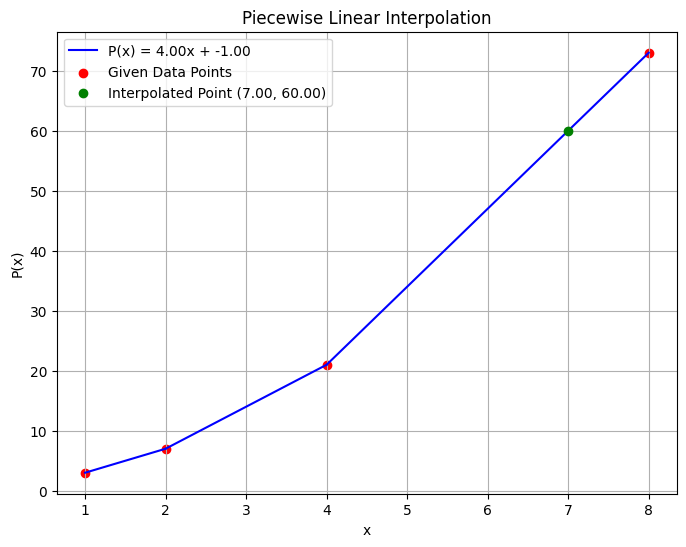

In [263]:
# Plot the interpolation
plot_interpolation(x_data, y_data, polynomials, x_interp, y_interp)